In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import cmocean

from nese.verify.maps import draw_cells, projection, set_region

In [2]:
from importlib.resources import files
plt.style.use(files("nese.verify") / "nese.mplstyle")

In [3]:
ds = xr.open_zarr("runs/v0/inference-validation/forecast.zarr/")

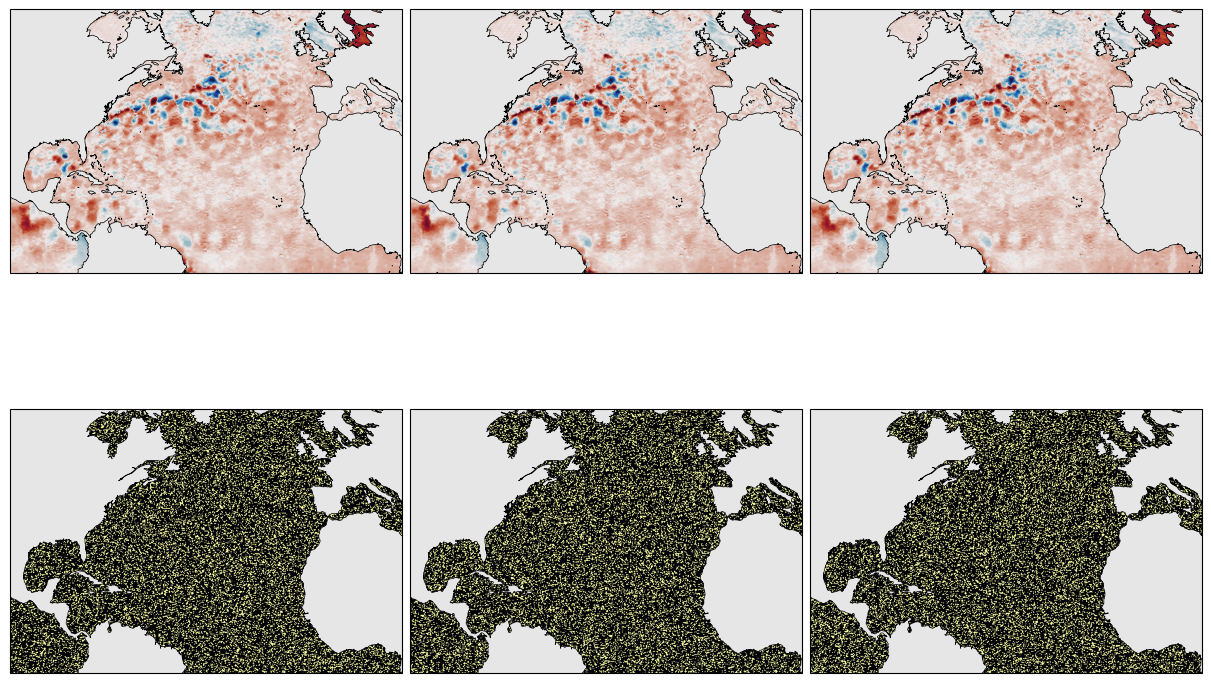

In [4]:
region = "north_atlantic"
time = "2020-03-02T12"

nrows = 2
fig, axs = plt.subplots(nrows, 3, figsize=(12,4*nrows), subplot_kw={"projection": projection(region)})

for fhr, axT, axB in zip(ds.fhr.values, axs[0], axs[1]):
    set_region(axT, region)
    plotme = ds["sla"].sel(t0=time).load().sel(fhr=fhr)
    draw_cells(
        ax=axT,
        values=plotme,
        vmin=-.5,
        vmax=.5,
        cmap="cmo.balance",
        attrs=ds.attrs,
    )
    set_region(axB, region)
    maskme = ds["input_hidden"].sel(t0=time).load().sel(fhr=fhr)
    draw_cells(
        ax=axB,
        values=maskme,
        vmin=0,
        vmax=1,
        attrs=ds.attrs,
    )

## Imprint of the input mask

The v0 checkpoint on one date, run twice by `slurm/imprint/imprint.sh`: unmasked, and with `mask_fraction: 0.25`. Their difference is what hiding the observations changes in the estimate.

In [5]:
unmasked = xr.open_zarr("runs/v0/imprint/unmasked/forecast.zarr")
masked = xr.open_zarr("runs/v0/imprint/masked/forecast.zarr")
imprint = (masked["sla"] - unmasked["sla"]).squeeze("t0")

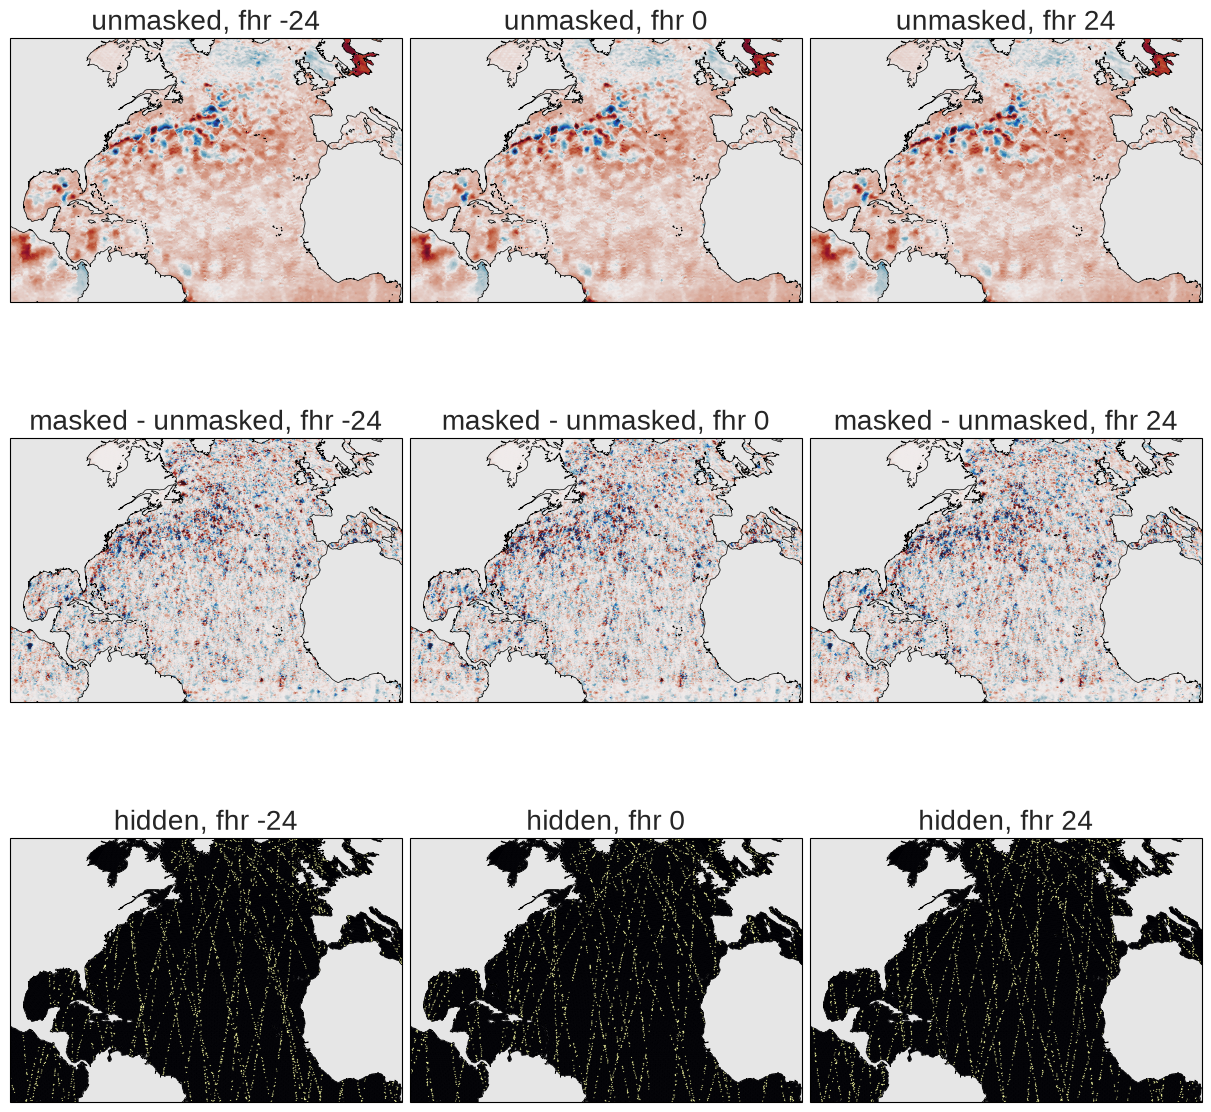

In [6]:
region = "north_atlantic"

panels = [
    ("unmasked", unmasked["sla"].squeeze("t0"), dict(vmin=-.5, vmax=.5, cmap="cmo.balance")),
    ("masked - unmasked", imprint, dict(vmin=-.05, vmax=.05, cmap="cmo.balance")),
    ("hidden", masked["input_hidden"].squeeze("t0"), dict(vmin=0, vmax=1)),
]
fig, axs = plt.subplots(len(panels), 3, figsize=(12, 4 * len(panels)), subplot_kw={"projection": projection(region)})
for row, (label, values, style) in zip(axs, panels):
    for fhr, ax in zip(masked.fhr.values, row):
        set_region(ax, region)
        draw_cells(ax=ax, values=values.sel(fhr=fhr), attrs=masked.attrs, **style)
        ax.set_title(f"{label}, fhr {fhr}")

In [7]:
# How large the imprint is on the hidden cells, and everywhere else
hidden = masked["input_hidden"].squeeze("t0") > 0
for fhr in masked.fhr.values:
    change = abs(imprint.sel(fhr=fhr))
    on, off = change.where(hidden.sel(fhr=fhr)), change.where(~hidden.sel(fhr=fhr))
    print(f"fhr {fhr:+d}: mean |change| on hidden cells {float(on.mean()):.4f} m, elsewhere {float(off.mean()):.4f} m")

fhr -24: mean |change| on hidden cells 0.0119 m, elsewhere 0.0072 m
fhr +0: mean |change| on hidden cells 0.0125 m, elsewhere 0.0074 m
fhr +24: mean |change| on hidden cells 0.0119 m, elsewhere 0.0073 m
